In [44]:
import pandas as pd
import numpy as np

df = pd.read_csv("./cs-training.csv")
df.drop(columns=["Unnamed: 0"], errors="ignore", inplace=True)
column_translation = {
    "SeriousDlqin2yrs": "2년 내 심각한 연체 여부",
    "RevolvingUtilizationOfUnsecuredLines": "무담보 신용한도 사용률",
    "age": "나이",
    "NumberOfTime30-59DaysPastDueNotWorse": "30~59일 연체 횟수",
    "DebtRatio": "부채 비율",
    "MonthlyIncome": "월 소득",
    "NumberOfOpenCreditLinesAndLoans": "개설된 신용거래 수",
    "NumberOfTimes90DaysLate": "90일 이상 연체 횟수",
    "NumberRealEstateLoansOrLines": "부동산 대출·신용한도 수",
    "NumberOfTime60-89DaysPastDueNotWorse": "60~89일 연체 횟수",
    "NumberOfDependents": "부양가족 수",
}
df.rename(columns=column_translation, inplace=True)
df.head()

,2년 내 심각한 연체 여부,무담보 신용한도 사용률,나이,30~59일 연체 횟수,부채 비율,월 소득,개설된 신용거래 수,90일 이상 연체 횟수,부동산 대출·신용한도 수,60~89일 연체 횟수,부양가족 수
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [ ]:
df.i

2년 내 심각한 연체 여부        0
무담보 신용한도 사용률          0
나이                    0
30~59일 연체 횟수          0
부채 비율                 0
월 소득              29731
개설된 신용거래 수            0
90일 이상 연체 횟수          0
부동산 대출·신용한도 수         0
60~89일 연체 횟수          0
부양가족 수             3924
dtype: int64

In [48]:
df[['월 소득', '부양가족 수']].describe()

,월 소득,부양가족 수
count,1.202690e+05,146076.000000
mean,6.670221e+03,0.757222
std,1.438467e+04,1.115086
min,0.000000e+00,0.000000
25%,3.400000e+03,0.000000
50%,5.400000e+03,0.000000
75%,8.249000e+03,1.000000
max,3.008750e+06,20.000000


In [27]:
# 나이 0살 삭제
df = df.drop(df[df["나이"] == 0].index).reset_index(drop=True)
df['나이'].describe()

count    149999.000000
mean         52.295555
std          14.771298
min          21.000000
25%          41.000000
50%          52.000000
75%          63.000000
max         109.000000
Name: 나이, dtype: float64

In [28]:
print(f"행 수: {df.shape[0]:,}")
print(f"열 수: {df.shape[1]:,}")

column_summary = pd.DataFrame(
    {
        "데이터 타입": df.dtypes.astype(str),
        "결측치 수": df.isna().sum(),
        "결측치 비율(%)": (df.isna().mean() * 100).round(2),
    }
).rename_axis("컬럼명")
column_summary

행 수: 149,999
열 수: 11


,데이터 타입,결측치 수,결측치 비율(%)
컬럼명,,,
2년 내 심각한 연체 여부,int64,0,0.00
무담보 신용한도 사용률,float64,0,0.00
나이,int64,0,0.00
30~59일 연체 횟수,int64,0,0.00
부채 비율,float64,0,0.00
월 소득,float64,29731,19.82
개설된 신용거래 수,int64,0,0.00
90일 이상 연체 횟수,int64,0,0.00
부동산 대출·신용한도 수,int64,0,0.00


In [29]:
df['30~59일 연체 횟수'].value_counts().sort_index()

0     126018
1      16032
2       4598
3       1754
4        747
5        342
6        140
7         54
8         25
9         12
10         4
11         1
12         2
13         1
96         5
98       264
Name: 30~59일 연체 횟수, dtype: int64

In [30]:
summary = df.describe().rename(
    index={
        "count": "개수",
        "mean": "평균",
        "std": "표준편차",
        "min": "최솟값",
        "25%": "25% 분위수",
        "50%": "중앙값",
        "75%": "75% 분위수",
        "max": "최댓값",
    }
).rename_axis("통계량")
summary

,2년 내 심각한 연체 여부,무담보 신용한도 사용률,나이,30~59일 연체 횟수,부채 비율,월 소득,개설된 신용거래 수,90일 이상 연체 횟수,부동산 대출·신용한도 수,60~89일 연체 횟수,부양가족 수
통계량,,,,,,,,,,,
개수,149999.000000,149999.000000,149999.000000,149999.000000,149999.000000,1.202680e+05,149999.000000,149999.000000,149999.000000,149999.000000,146075.000000
평균,0.066840,6.048472,52.295555,0.421029,353.007426,6.670227e+03,8.452776,0.265975,1.018233,0.240388,0.757214
표준편차,0.249746,249.756203,14.771298,4.192795,2037.825113,1.438473e+04,5.145964,4.169318,1.129772,4.155193,1.115085
최솟값,0.000000,0.000000,21.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25% 분위수,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
중앙값,0.000000,0.154176,52.000000,0.000000,0.366503,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75% 분위수,0.000000,0.559044,63.000000,0.000000,0.868257,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
최댓값,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [31]:
df.head(10)

,2년 내 심각한 연체 여부,무담보 신용한도 사용률,나이,30~59일 연체 횟수,부채 비율,월 소득,개설된 신용거래 수,90일 이상 연체 횟수,부동산 대출·신용한도 수,60~89일 연체 횟수,부양가족 수
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
5,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0
6,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0
7,0,0.754464,39,0,0.209940,3500.0,8,0,0,0,0.0
8,0,0.116951,27,0,46.000000,NaN,2,0,0,0,NaN
9,0,0.189169,57,0,0.606291,23684.0,9,0,4,0,2.0


In [32]:
df.head()

,2년 내 심각한 연체 여부,무담보 신용한도 사용률,나이,30~59일 연체 횟수,부채 비율,월 소득,개설된 신용거래 수,90일 이상 연체 횟수,부동산 대출·신용한도 수,60~89일 연체 횟수,부양가족 수
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [33]:
# 타깃(라벨)은 '2년 내 심각한 연체 여부'입니다.

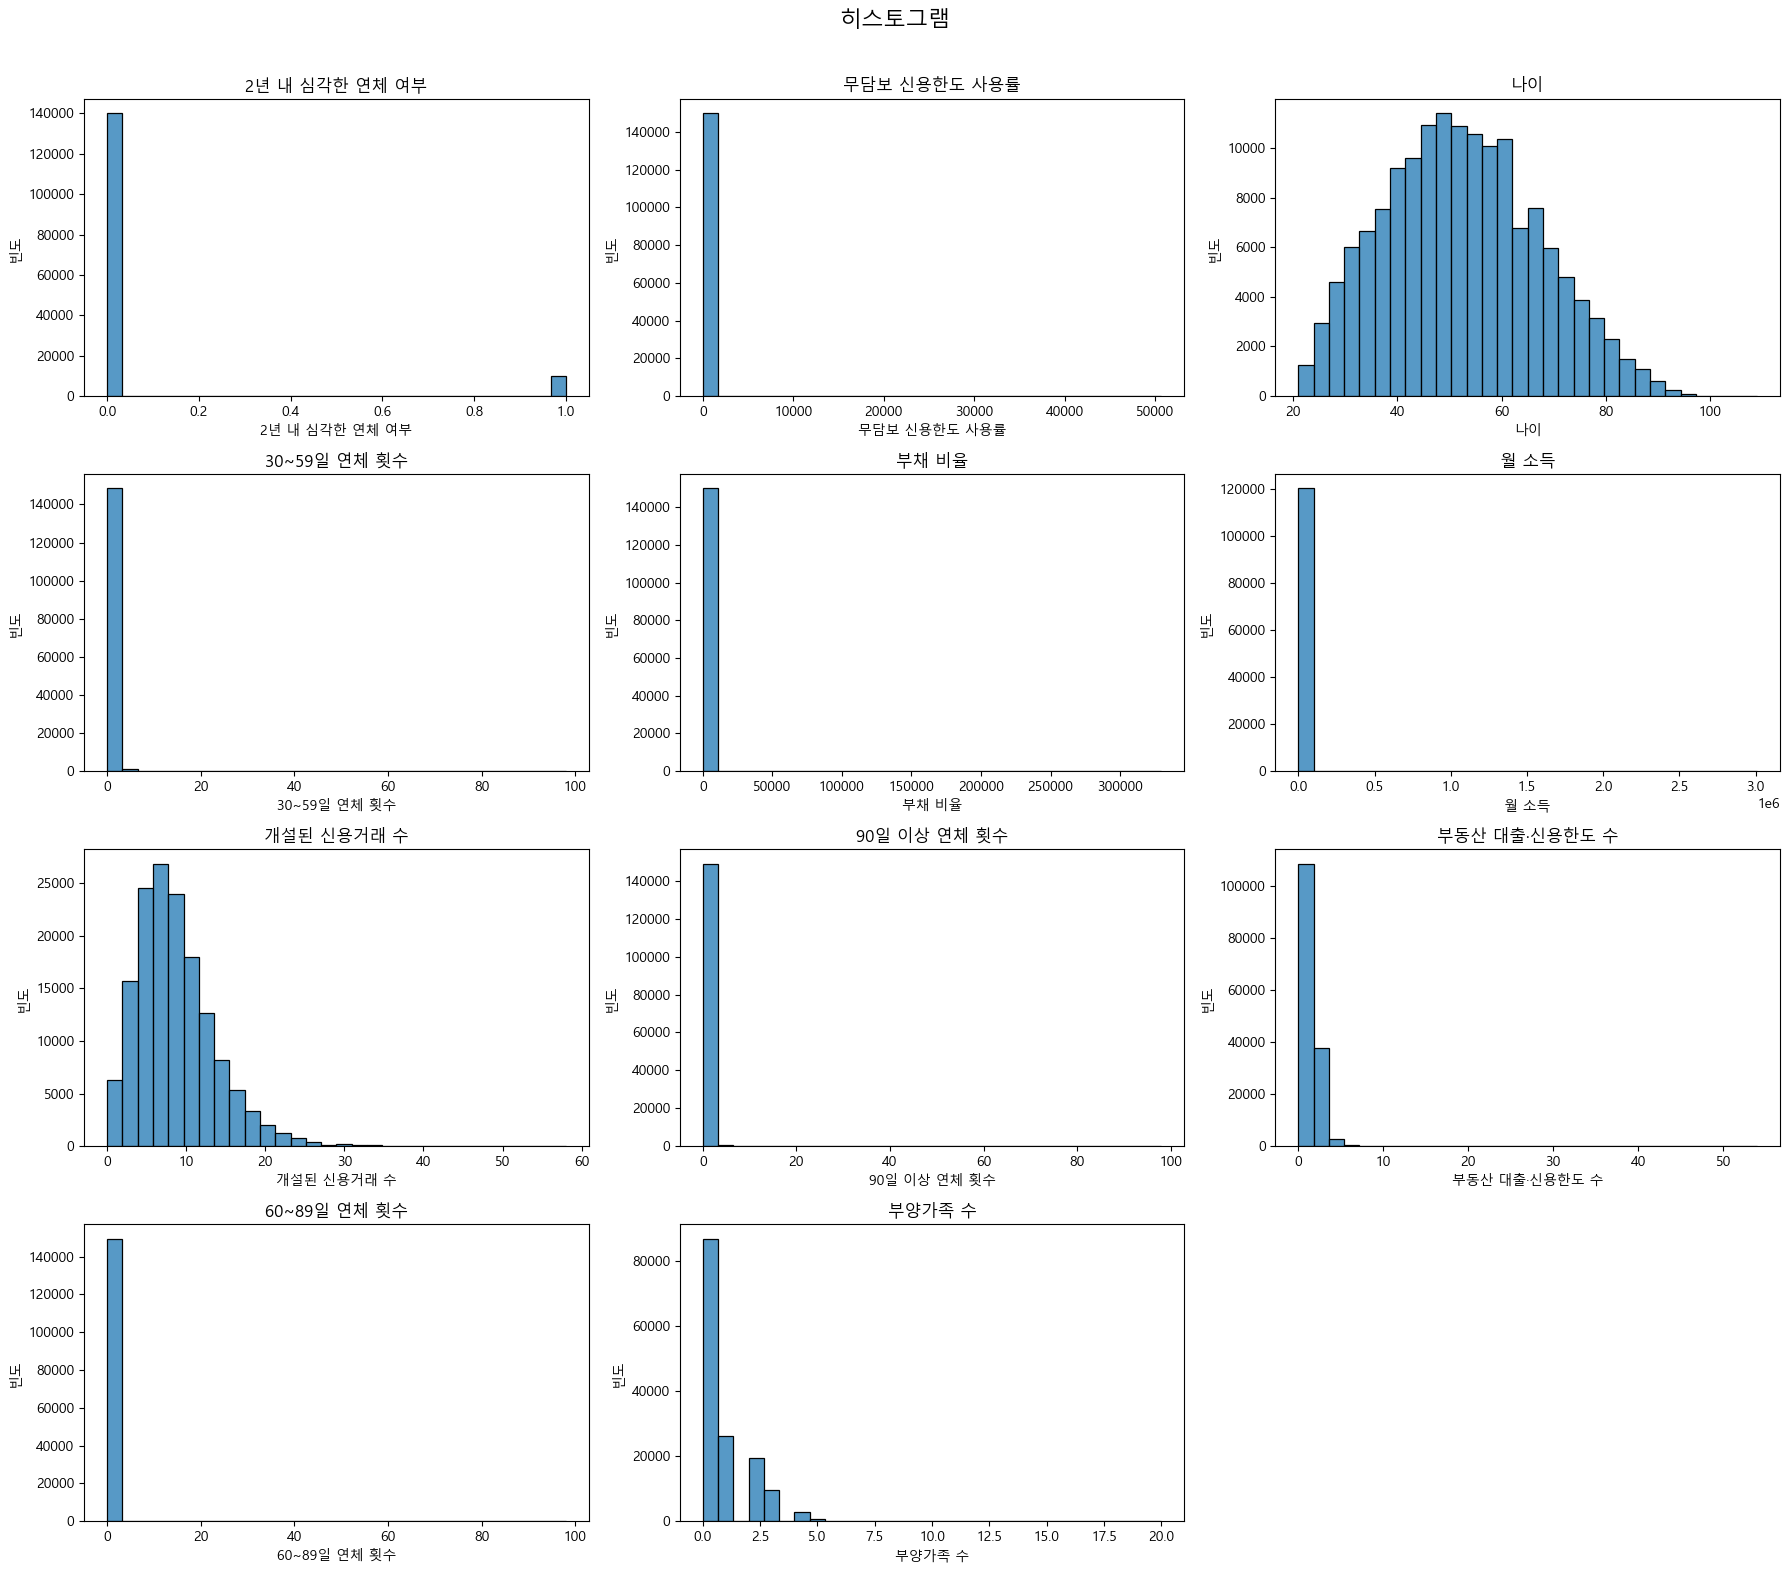

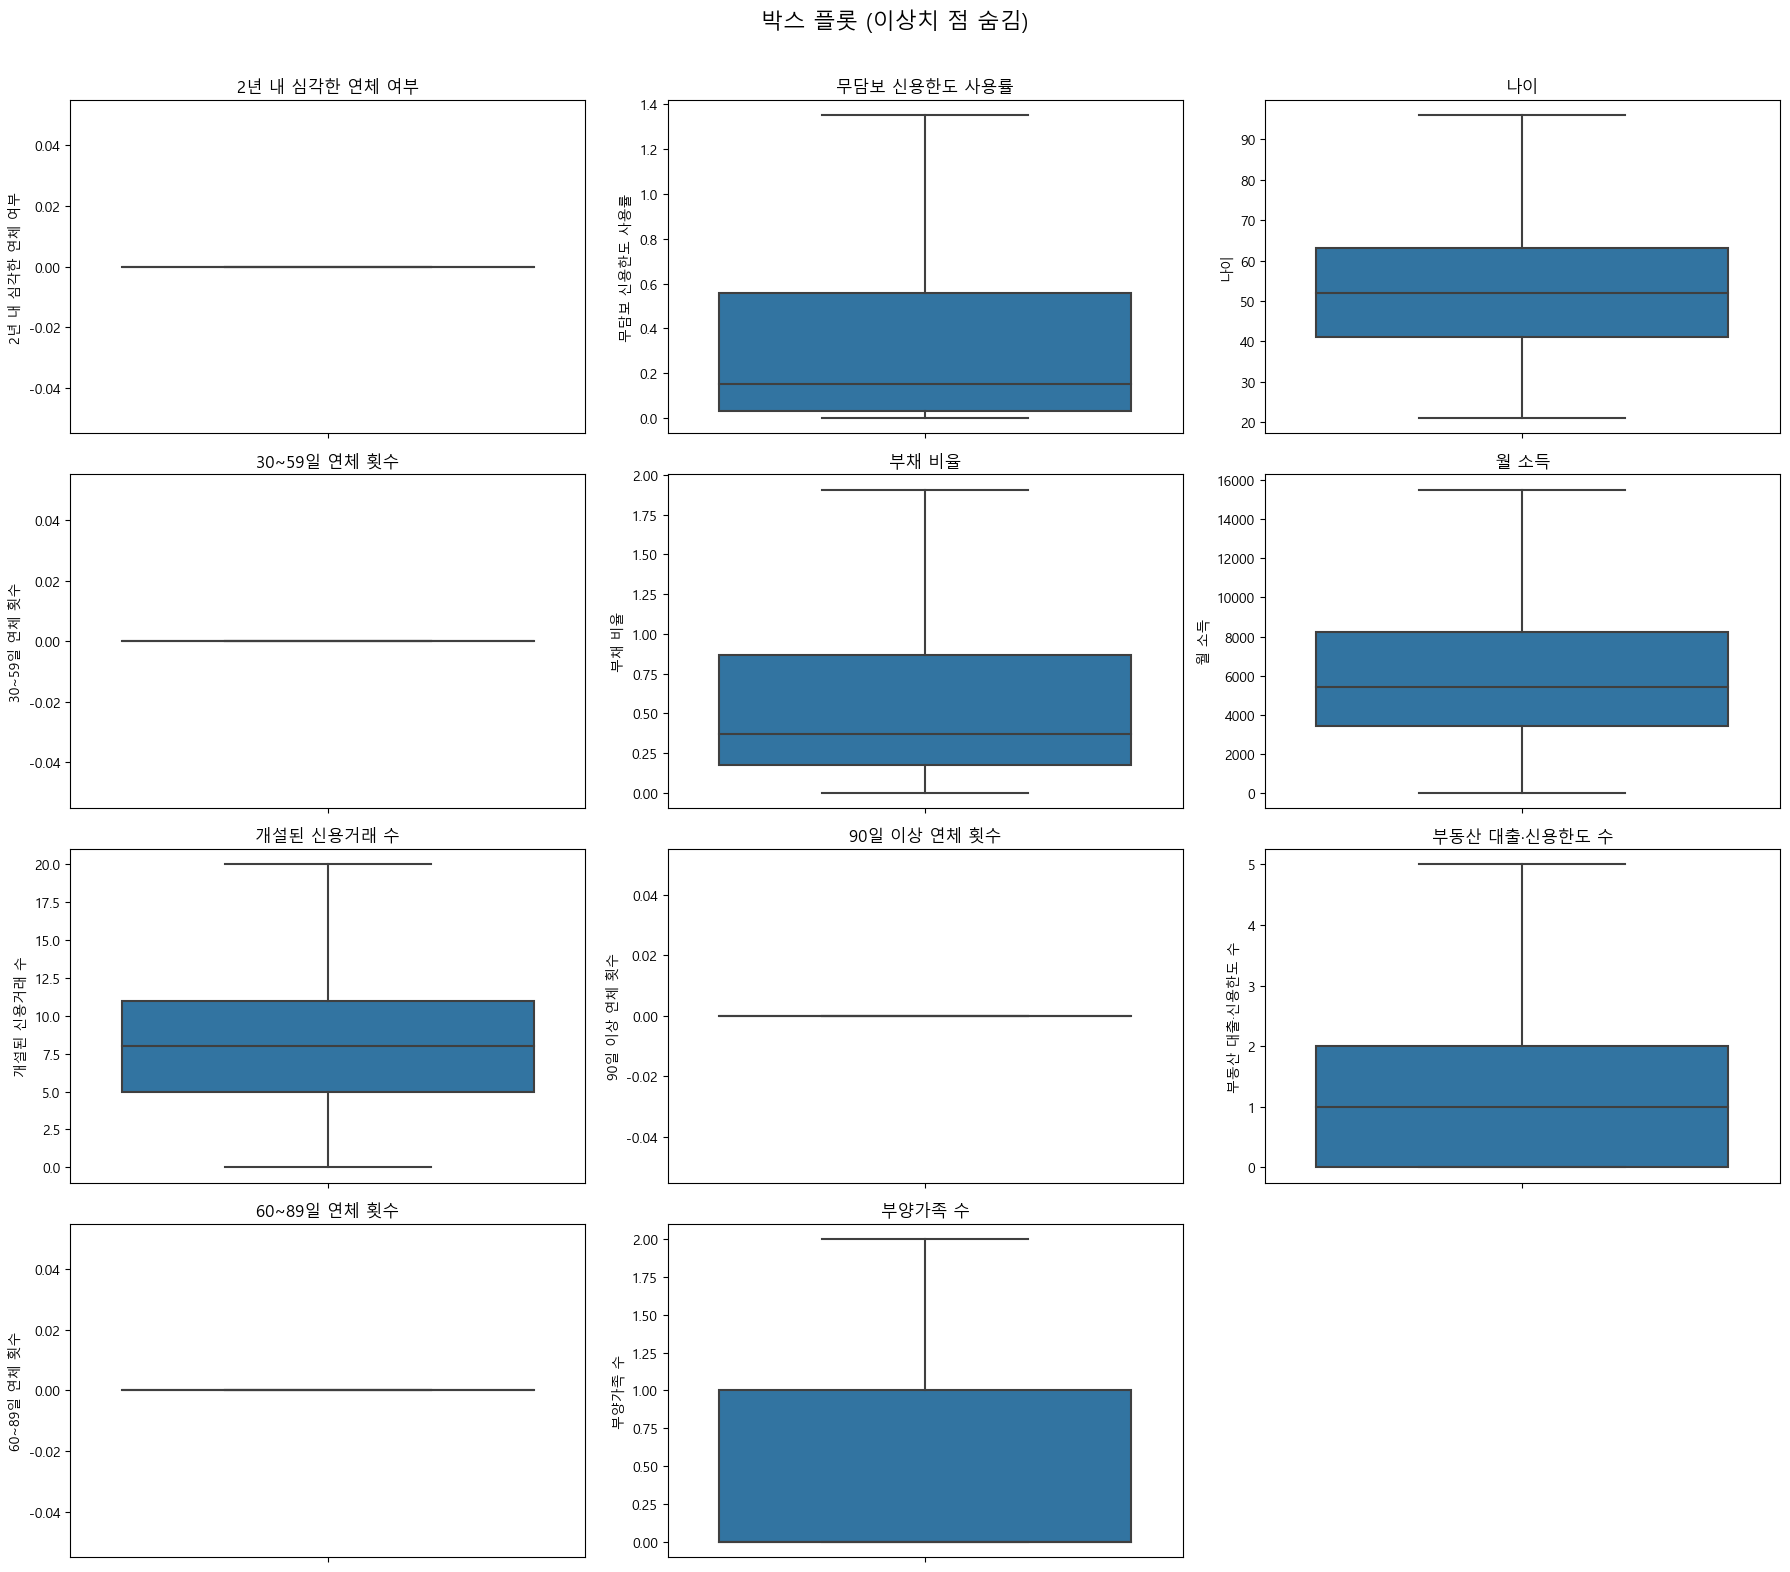

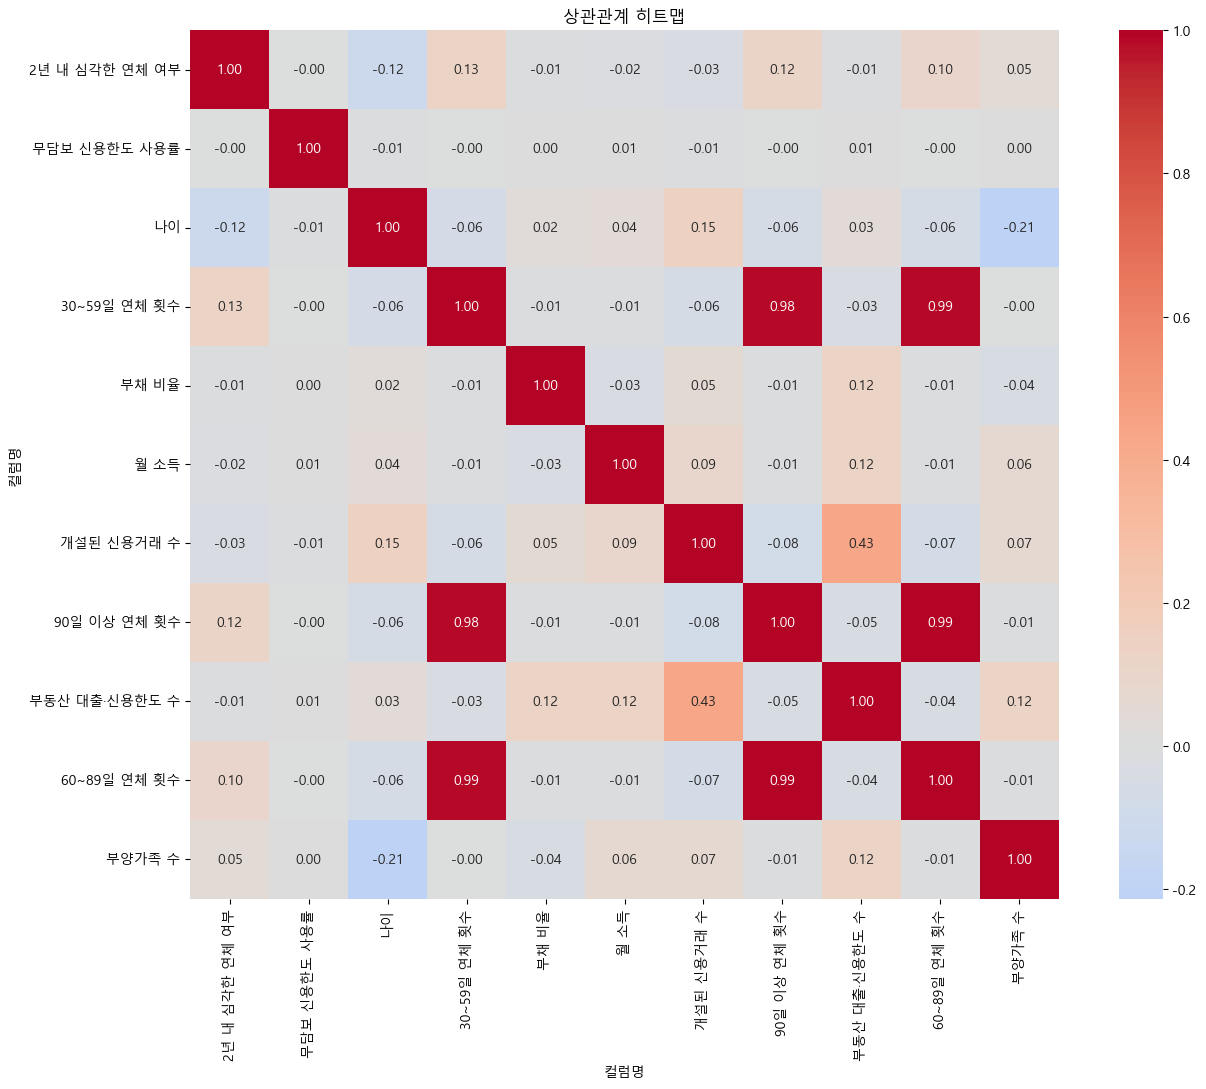

In [34]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

numeric_columns = df.select_dtypes(include="number").columns
plot_columns = 3
plot_rows = math.ceil(len(numeric_columns) / plot_columns)

fig, axes = plt.subplots(plot_rows, plot_columns, figsize=(18, 4 * plot_rows))
axes = axes.flatten()
for column, ax in zip(numeric_columns, axes):
    sns.histplot(data=df, x=column, bins=30, ax=ax)
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("빈도")
for ax in axes[len(numeric_columns):]:
    ax.remove()
fig.suptitle("히스토그램", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig, axes = plt.subplots(plot_rows, plot_columns, figsize=(18, 4 * plot_rows))
axes = axes.flatten()
for column, ax in zip(numeric_columns, axes):
    sns.boxplot(y=df[column], showfliers=False, ax=ax)
    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel(column)
for ax in axes[len(numeric_columns):]:
    ax.remove()
fig.suptitle("박스 플롯 (이상치 점 숨김)", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

correlation = df[numeric_columns].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("상관관계 히트맵")
plt.xlabel("컬럼명")
plt.ylabel("컬럼명")
plt.tight_layout()
plt.show()

In [35]:
df["부양가족 수"].value_counts()
df['부양가족 수'].isna().sum()

3924

In [36]:
df["월 소득"].value_counts()

5000.0     2757
4000.0     2106
6000.0     1933
3000.0     1758
0.0        1634
           ... 
16084.0       1
10523.0       1
55250.0       1
9242.0        1
7647.0        1
Name: 월 소득, Length: 13594, dtype: int64

In [37]:
df["월 소득"] = df["월 소득"].fillna(df["월 소득"].median())
df['월 소득'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 149999 entries, 0 to 149998
Series name: 월 소득
Non-Null Count   Dtype  
--------------   -----  
149999 non-null  float64
dtypes: float64(1)
memory usage: 1.1 MB


In [38]:
df['부양가족 수'] = df['부양가족 수'].fillna(df['부양가족 수'].median())
df["부양가족 수"].isna().sum()

0

## 모델 학습과 성능 비교

이 데이터의 정답 컬럼은 0/1로 된 이진 라벨이므로, 일반 선형회귀가 아니라 분류 모델을 사용합니다. 책에 나온 LogisticRegression은 이름에 회귀가 들어가지만 이진 분류 모델입니다.

여러 모델은 학습 데이터로 학습하고 검증 데이터의 평균정밀도(AP)를 기준으로 비교합니다. 마지막 테스트 데이터는 최종 모델을 한 번 평가하는 데만 사용합니다.

In [39]:
# 예측할 정답 컬럼의 이름을 지정합니다.
target_column = "2년 내 심각한 연체 여부"

delinquency_columns = ["30~59일 연체 횟수", "60~89일 연체 횟수", "90일 이상 연체 횟수"]

# 30~59일 연체 횟수 기준: 96이면 1, 98이면 2, 나머지는 0
df["이상"] = np.select(
    [df["30~59일 연체 횟수"] == 96, df["30~59일 연체 횟수"] == 98],
    [1, 2],
    default=0,
)
print(df["이상"].value_counts().sort_index())

# 바꾸기 전 연체 횟수 변수의 96, 98 값이 얼마나 있는지 확인합니다.
for column in delinquency_columns:
    unusual_values = df.loc[df[column] >= 90, column].value_counts().sort_index()
    print(f"{column}의 90 이상 값: {unusual_values.to_dict()}")

# 특이값 96, 98을 바꿉니다: 30~59일·90일 이상은 24, 60~89일은 12
for column in ["30~59일 연체 횟수", "90일 이상 연체 횟수"]:
    df.loc[df[column].isin([96, 98]), column] = 24
df.loc[df["60~89일 연체 횟수"].isin([96, 98]), "60~89일 연체 횟수"] = 12

# 바꾼 뒤 각 컬럼의 최댓값을 확인합니다.
print(df[delinquency_columns].max())

# 정답 컬럼과 CSV에 들어온 행 번호 컬럼은 입력 변수에서 제외합니다.
X = df.drop(columns=[target_column, "Unnamed: 0"], errors="ignore").copy()

# 0/1 정답값을 y로 분리합니다.
y = df[target_column].astype(int).copy()

# 각 정답값의 건수와 비율을 표로 확인합니다.
target_counts = y.value_counts().sort_index()
target_summary = pd.DataFrame({
    "건수": target_counts,
    "비율(%)": (y.value_counts(normalize=True).sort_index() * 100).round(2),
})
target_summary.index.name = "연체 라벨"
display(target_summary)

0    149730
1         5
2       264
Name: 이상, dtype: int64
30~59일 연체 횟수의 90 이상 값: {96: 5, 98: 264}
60~89일 연체 횟수의 90 이상 값: {96: 5, 98: 264}
90일 이상 연체 횟수의 90 이상 값: {96: 5, 98: 264}
30~59일 연체 횟수    24
60~89일 연체 횟수    12
90일 이상 연체 횟수    24
dtype: int64


,건수,비율(%)
연체 라벨,,
0,139973,93.32
1,10026,6.68


In [ ]:
# df[df['이상'] == 1]
[df[41940:41946]]

,2년 내 심각한 연체 여부,무담보 신용한도 사용률,나이,30~59일 연체 횟수,부채 비율,월 소득,개설된 신용거래 수,90일 이상 연체 횟수,부동산 대출·신용한도 수,60~89일 연체 횟수,부양가족 수,이상
41940,0,0.909091,52,3,0.696371,6833.0,12,0,2,0,2.0,0
41941,0,0.584406,43,0,0.337922,10750.0,10,0,1,0,2.0,0
41942,1,0.980772,43,3,0.692598,5835.0,9,1,2,1,0.0,0
41943,0,0.103955,29,0,0.004658,7083.0,2,0,0,0,0.0,0
41944,1,1.000000,26,24,0.000000,5400.0,0,24,0,12,0.0,1
41945,0,0.011783,55,0,0.530772,3200.0,21,0,1,0,0.0,0


In [85]:
df.describe()

,2년 내 심각한 연체 여부,무담보 신용한도 사용률,나이,30~59일 연체 횟수,부채 비율,월 소득,개설된 신용거래 수,90일 이상 연체 횟수,부동산 대출·신용한도 수,60~89일 연체 횟수,부양가족 수,이상
count,149999.000000,149999.000000,149999.000000,149999.000000,149999.000000,1.499990e+05,149999.000000,149999.000000,149999.000000,149999.000000,149999.000000,149999.000000
mean,0.066840,6.048472,52.295555,0.288389,353.007426,6.418458e+03,8.452776,0.133334,1.018233,0.086227,0.737405,0.003553
std,0.249746,249.756203,14.771298,1.223165,2037.825113,1.289044e+04,5.145964,1.121909,1.129772,0.603122,1.107020,0.084029
min,0.000000,0.000000,21.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.903000e+03,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154176,52.000000,0.000000,0.366503,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,0.000000,0.559044,63.000000,0.000000,0.868257,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000,0.000000
max,1.000000,50708.000000,109.000000,24.000000,329664.000000,3.008750e+06,58.000000,24.000000,54.000000,12.000000,20.000000,2.000000


### 학습·검증·테스트 데이터 나누기

데이터를 60% 학습, 20% 검증, 20% 테스트로 나눕니다. stratify 옵션으로 각 묶음의 연체 비율을 비슷하게 유지합니다. 검증 데이터로 모델을 고르고, 테스트 데이터는 마지막 성능 확인에만 사용합니다.

In [86]:
from sklearn.model_selection import train_test_split

# 우선 전체 데이터의 20%를 최종 테스트용으로 따로 보관합니다.
X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# 남은 80%에서 25%를 검증용으로 떼어 전체 기준 20%가 되게 합니다.
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development,
    y_development,
    test_size=0.25,
    random_state=42,
    stratify=y_development,
)

# 데이터 크기와 각 묶음의 양성 비율을 확인합니다.
print(f"학습 데이터: {X_train.shape}, 연체 비율: {y_train.mean():.3%}")
print(f"검증 데이터: {X_valid.shape}, 연체 비율: {y_valid.mean():.3%}")
print(f"테스트 데이터: {X_test.shape}, 연체 비율: {y_test.mean():.3%}")

학습 데이터: (89999, 11), 연체 비율: 6.685%
검증 데이터: (30000, 11), 연체 비율: 6.683%
테스트 데이터: (30000, 11), 연체 비율: 6.683%


### 전처리와 비교할 모델 준비

월 소득과 부양가족 수의 결측값은 학습 데이터에서 계산한 중앙값으로 채우고, 원래 결측이었는지도 표시합니다. 거리 기반 KNN과 로지스틱 회귀에는 표준화를 적용하고, 트리 계열에는 표준화를 적용하지 않습니다.

정확도만으로는 양성 비율이 낮은 데이터의 모델을 고르기 어려우므로 평균정밀도(AP)를 주 비교 기준으로 사용합니다. ROC-AUC, 정확도, 정밀도, 재현율, F1도 함께 기록합니다.

In [87]:
import time

from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# 선형·거리 기반 모델용 파이프라인: 중앙값 대체, 결측 표시, 표준화 순서로 처리합니다.
def make_scaled_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("model", estimator),
    ])

# 트리 계열 모델용 파이프라인: 크기 조정은 하지 않고 결측값만 처리합니다.
def make_tree_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", estimator),
    ])

# 모델별 성능과 학습된 객체를 저장할 공간을 만듭니다.
model_results = {}
fitted_models = {}

# 모델을 학습하고 검증 데이터에서 공통 지표를 계산하는 함수입니다.
def fit_and_evaluate_validation(model_name, estimator):
    # 학습 시작 시간을 기록합니다.
    start_time = time.perf_counter()

    # 학습 데이터로만 전처리 기준과 모델을 학습합니다.
    estimator.fit(X_train, y_train)

    # 검증 데이터의 연체 확률을 계산합니다.
    probabilities = estimator.predict_proba(X_valid)[:, 1]

    # 확률 0.5를 기준으로 임시 분류값을 만듭니다.
    predictions = (probabilities >= 0.5).astype(int)

    # 검증 데이터의 지표를 저장합니다.
    model_results[model_name] = {
        "모델": model_name,
        "평균정밀도(AP)": average_precision_score(y_valid, probabilities),
        "ROC-AUC": roc_auc_score(y_valid, probabilities),
        "정확도(임계값 0.5)": accuracy_score(y_valid, predictions),
        "정밀도(임계값 0.5)": precision_score(y_valid, predictions, zero_division=0),
        "재현율(임계값 0.5)": recall_score(y_valid, predictions, zero_division=0),
        "F1(임계값 0.5)": f1_score(y_valid, predictions, zero_division=0),
        "소요 시간(초)": time.perf_counter() - start_time,
    }

    # 가장 좋은 모델을 나중에 테스트할 수 있도록 학습된 객체를 저장합니다.
    fitted_models[model_name] = estimator

    # 실행 중 어느 모델이 끝났는지 간단히 표시합니다.
    print(f"{model_name} 완료 | AP={model_results[model_name]['평균정밀도(AP)']:.4f}")

In [93]:
# 책의 LogisticRegression 예제를 사용하되 클래스 불균형 가중치를 적용합니다.
models = {
    "로지스틱 회귀": make_scaled_pipeline(
        LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    ),

    # KNN은 거리 계산을 사용하므로 표준화 파이프라인을 적용합니다.
    "K최근접 이웃": make_scaled_pipeline(
        KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=-1)
    ),

    # 단일 결정트리는 깊이와 최소 리프 크기를 제한해 과적합을 줄입니다.
    "결정 트리": make_tree_pipeline(
        DecisionTreeClassifier(
            max_depth=10,
            min_samples_leaf=30,
            class_weight="balanced",
            random_state=42,
        )
    ),

    # 랜덤 포레스트는 여러 결정트리의 결과를 모아 예측합니다.
    "랜덤 포레스트": make_tree_pipeline(
        RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=10,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42,
        )
    ),

    # 랜덤포레스트1은 학습 데이터 3겹 교차검증 AP로 탐색해 찾은 설정입니다.
    "랜덤 포레스트1": make_tree_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            max_depth=16,
            min_samples_leaf=25,
            max_features="sqrt",
            class_weight=None,
            n_jobs=-1,
            random_state=42,
        )
    ),

    # AdaBoost는 얕은 결정트리를 순차적으로 학습해 앞선 오류에 집중합니다.
    "AdaBoost": make_tree_pipeline(
        AdaBoostClassifier(
            base_estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
            n_estimators=100,
            learning_rate=0.05,
            random_state=42,
        )
    ),
}

# 먼저 기본 분류 모델들을 검증 데이터에서 비교합니다.
for model_name, estimator in models.items():
    fit_and_evaluate_validation(model_name, estimator)

로지스틱 회귀 완료 | AP=0.3626
K최근접 이웃 완료 | AP=0.2998
결정 트리 완료 | AP=0.3578
랜덤 포레스트 완료 | AP=0.4095
랜덤 포레스트1 완료 | AP=0.4160
AdaBoost 완료 | AP=0.3830


In [94]:
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# 양성과 음성의 비율을 계산해 XGBoost의 클래스 가중치로 사용합니다.
positive_weight = (y_train == 0).sum() / (y_train == 1).sum()

# XGBoost는 히스토그램 방식으로 학습하고 불균형 데이터용 가중치를 적용합니다.
models["XGBoost"] = make_tree_pipeline(
    XGBClassifier(
        n_estimators=350,
        max_depth=4,
        min_child_weight=15,
        learning_rate=0.02,
        subsample=0.8601,
        colsample_bytree=0.67611,
        scale_pos_weight=positive_weight,
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=4,
        random_state=42,
    )
)

# LightGBM은 balanced 가중치와 리프 수 제한을 사용합니다.
models["LightGBM"] = make_tree_pipeline(
    LGBMClassifier(
        n_estimators=140,
        learning_rate=0.05,
        num_leaves=31,
        class_weight="balanced",
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        n_jobs=-1,
        verbosity=-1,
        random_state=42,
    )
)

# 두 부스팅 모델도 같은 학습·검증 분할과 지표로 평가합니다.
for model_name in ["XGBoost", "LightGBM"]:
    fit_and_evaluate_validation(model_name, models[model_name])

XGBoost 완료 | AP=0.4169
LightGBM 완료 | AP=0.4131


In [ ]:
# 소프트 보팅은 로지스틱 회귀와 KNN의 예측 확률을 평균냅니다.
models["소프트 보팅"] = VotingClassifier(
    estimators=[
        ("forest", models["랜덤 포레스트1"]),
        ("xgboost", models["XGBoost"]),
        ("lightgbm", models["LightGBM"]),
        ("adaboost", models["AdaBoost"]),
    ],
    voting="soft",
    n_jobs=1,
)
models["소프트 보팅1"] = VotingClassifier(
    estimators=[
        ("forest", models["랜덤 포레스트1"]),
        ("xgboost", models["XGBoost"]),
        ("lightgbm", models["LightGBM"]),
    ],
    voting="soft",
    n_jobs=1,
)

# 소프트 보팅 모델을 검증 데이터에서 평가합니다.
fit_and_evaluate_validation("소프트 보팅", models["소프트 보팅"])

소프트 보팅 완료 | AP=0.4179


In [96]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# 소프트 보팅 안의 두 모델 설정과, 두 모델 확률을 섞는 비율(weights)을 함께 탐색합니다.
# 보팅 안 모델의 설정은 "보팅 이름__파이프라인 단계__설정" 형태로 지정합니다.
voting_search_space = {
    "logistic__model__C": loguniform(1e-3, 1e2),
    "knn__model__n_neighbors": randint(15, 300),
    "knn__model__weights": ["uniform", "distance"],
    "weights": [[1, 1], [2, 1], [1, 2], [3, 1], [1, 3]],
}

# 학습 데이터 안에서 층화 3겹 교차검증 AP로 20개 조합을 비교합니다.
voting_search = RandomizedSearchCV(
    VotingClassifier(
        estimators=[
            ("logistic", make_scaled_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42))),
            ("knn", make_scaled_pipeline(KNeighborsClassifier(n_jobs=1))),
        ],
        voting="soft",
    ),
    voting_search_space,
    n_iter=20,
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=4,
    random_state=42,
)
voting_search.fit(X_train, y_train)
print("최적 설정:", voting_search.best_params_)
print(f"교차검증 평균 AP: {voting_search.best_score_:.4f}")

# 찾은 설정의 소프트 보팅을 기존 모델과 같은 검증 기준으로 평가합니다.
models["소프트 보팅 (튜닝)"] = voting_search.best_estimator_
fit_and_evaluate_validation("소프트 보팅 (튜닝)", models["소프트 보팅 (튜닝)"])

KeyboardInterrupt: 

### Hyperopt로 XGBoost 하이퍼파라미터 탐색

4_5와 4_6의 Hyperopt 방식을 적용합니다. 학습 데이터 안에서 층화 3겹 교차검증으로 설정을 고르고, 검증 데이터와 테스트 데이터는 탐색 과정에서 사용하지 않습니다. 실행 시간을 고려해 우선 10개 조합을 비교합니다.

In [ ]:
from hyperopt import STATUS_OK, Trials, fmin, hp, tpe
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 탐색할 트리 깊이, 리프 조건, 학습률, 열·행 샘플 비율을 정의합니다.
xgb_search_space = {
    "max_depth": hp.quniform("max_depth", 2, 7, 1),
    "min_child_weight": hp.quniform("min_child_weight", 1, 10, 1),
    "learning_rate": hp.loguniform("learning_rate", np.log(0.02), np.log(0.15)),
    "colsample_bytree": hp.uniform("colsample_bytree", 0.6, 1.0),
    "subsample": hp.uniform("subsample", 0.7, 1.0),
}

# 매 조합을 학습 데이터의 동일한 층화 3겹 교차검증으로 평가합니다.
xgb_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 평균정밀도 계산에는 연체(양성) 확률 한 열만 전달합니다.
def average_precision_scorer(estimator, X_fold, y_fold):
    positive_probabilities = estimator.predict_proba(X_fold)[:, 1]
    return average_precision_score(y_fold, positive_probabilities)

# Hyperopt가 호출할 목적 함수입니다. 평균정밀도를 높이기 위해 음수 점수를 최소화합니다.
def xgb_objective(search_params):
    candidate = make_tree_pipeline(
        XGBClassifier(
            n_estimators=200,
            max_depth=int(search_params["max_depth"]),
            min_child_weight=float(search_params["min_child_weight"]),
            learning_rate=float(search_params["learning_rate"]),
            colsample_bytree=float(search_params["colsample_bytree"]),
            subsample=float(search_params["subsample"]),
            scale_pos_weight=positive_weight,
            objective="binary:logistic",
            eval_metric="aucpr",
            tree_method="hist",
            n_jobs=4,
            random_state=42,
        )
    )

    # 사용자 정의 점수 함수로 각 fold의 양성 확률만 평가합니다.
    fold_scores = cross_val_score(
        candidate,
        X_train,
        y_train,
        cv=xgb_cv,
        scoring=average_precision_scorer,
        n_jobs=1,
    )

    # Hyperopt는 loss를 최소화하므로 AP에 음수를 붙여 반환합니다.
    return {"loss": -float(fold_scores.mean()), "status": STATUS_OK}

# 탐색 기록을 저장하고 TPE 알고리즘으로 10개 설정을 시험합니다.
hyperopt_trials = Trials()
best_xgb_params = fmin(
    fn=xgb_objective,
    space=xgb_search_space,
    algo=tpe.suggest,
    max_evals=10,
    trials=hyperopt_trials,
    rstate=np.random.default_rng(seed=42),
    show_progressbar=False,
)

# 선택된 설정을 보기 쉬운 숫자 형태로 출력합니다.
print({
    "max_depth": int(best_xgb_params["max_depth"]),
    "min_child_weight": int(best_xgb_params["min_child_weight"]),
    "learning_rate": round(best_xgb_params["learning_rate"], 5),
    "colsample_bytree": round(best_xgb_params["colsample_bytree"], 5),
    "subsample": round(best_xgb_params["subsample"], 5),
})

# 탐색된 설정으로 최종 XGBoost 후보를 구성합니다.
models["XGBoost (Hyperopt)"] = make_tree_pipeline(
    XGBClassifier(
        n_estimators=200,
        max_depth=int(best_xgb_params["max_depth"]),
        min_child_weight=float(best_xgb_params["min_child_weight"]),
        learning_rate=float(best_xgb_params["learning_rate"]),
        colsample_bytree=float(best_xgb_params["colsample_bytree"]),
        subsample=float(best_xgb_params["subsample"]),
        scale_pos_weight=positive_weight,
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=4,
        random_state=42
    )
)

# 튜닝 모델도 검증 데이터에서 다른 후보들과 같은 기준으로 평가합니다.
fit_and_evaluate_validation("XGBoost (Hyperopt)", models["XGBoost (Hyperopt)"])

{'max_depth': 3, 'min_child_weight': 2, 'learning_rate': 0.04017, 'colsample_bytree': 0.73527, 'subsample': 0.85087}


XGBoost (Hyperopt) 완료 | AP=0.4119


### GridSearchCV로 XGBoost 하이퍼파라미터 탐색

트리 깊이, 학습률, 최소 리프 가중치, 행 샘플 비율의 조합 36개를 모두 시험합니다. Hyperopt와 같이 학습 데이터 안에서 층화 3겹 교차검증의 평균정밀도(AP)로 설정을 고르고, 검증·테스트 데이터는 탐색에 사용하지 않습니다.

In [ ]:
from sklearn.model_selection import GridSearchCV

# 탐색할 XGBoost 설정 후보입니다. 파이프라인 안의 모델이므로 이름 앞에 "model__"을 붙입니다.
xgb_param_grid = {
    "model__max_depth": [3, 4, 5],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__min_child_weight": [1, 5],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8],
}

# 나머지 설정은 기존 XGBoost와 같게 두고, 위 후보만 바꿔 가며 학습합니다.
xgb_grid = GridSearchCV(
    make_tree_pipeline(
        XGBClassifier(
            n_estimators=200,
            scale_pos_weight=positive_weight,
            objective="binary:logistic",
            eval_metric="aucpr",
            tree_method="hist",
            n_jobs=4,
            random_state=42,
        )
    ),
    param_grid=xgb_param_grid,
    scoring="average_precision",
    cv=xgb_cv,
    n_jobs=4,
)

# 학습 데이터로만 36개 조합 × 3겹 = 108번 학습합니다.
xgb_grid.fit(X_train, y_train)
print("최적 설정:", xgb_grid.best_params_)
print(f"교차검증 평균 AP: {xgb_grid.best_score_:.4f}")

# 교차검증 점수가 높은 상위 5개 조합을 확인합니다.
grid_results = pd.DataFrame(xgb_grid.cv_results_).sort_values("rank_test_score")
display(grid_results[["params", "mean_test_score", "std_test_score"]].head(5))

# 최적 설정의 모델도 검증 데이터에서 다른 후보들과 같은 기준으로 평가합니다.
models["XGBoost (GridSearch)"] = xgb_grid.best_estimator_
fit_and_evaluate_validation("XGBoost (GridSearch)", models["XGBoost (GridSearch)"])

최적 설정: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__min_child_weight': 5, 'model__subsample': 1.0}
교차검증 평균 AP: 0.3943


,params,mean_test_score,std_test_score
19,"{'model__colsample_bytree': 0.8, 'model__learn...",0.394343,0.004321
18,"{'model__colsample_bytree': 0.8, 'model__learn...",0.394196,0.004208
7,"{'model__colsample_bytree': 0.8, 'model__learn...",0.393916,0.005047
6,"{'model__colsample_bytree': 0.8, 'model__learn...",0.393564,0.005047
10,"{'model__colsample_bytree': 0.8, 'model__learn...",0.393354,0.006828


XGBoost (GridSearch) 완료 | AP=0.4124


In [ ]:
# 검증 데이터의 평균정밀도(AP)를 기준으로 모든 후보를 정렬합니다.
validation_results = (
    pd.DataFrame(model_results.values())
    .sort_values("평균정밀도(AP)", ascending=False)
    .reset_index(drop=True)
)

# 숫자 지표를 읽기 쉽게 표시합니다.
display(validation_results.style.format({
    "평균정밀도(AP)": "{:.4f}",
    "ROC-AUC": "{:.4f}",
    "정확도(임계값 0.5)": "{:.4f}",
    "정밀도(임계값 0.5)": "{:.4f}",
    "재현율(임계값 0.5)": "{:.4f}",
    "F1(임계값 0.5)": "{:.4f}",
    "소요 시간(초)": "{:.1f}",
}))

# 검증 AP가 가장 높은 모델을 선택합니다. 테스트 점수로 모델을 고르지 않습니다.
best_validation_name = validation_results.loc[0, "모델"]
print(f"검증 데이터 기준 선택 모델: {best_validation_name}")

,모델,평균정밀도(AP),ROC-AUC,정확도(임계값 0.5),정밀도(임계값 0.5),재현율(임계값 0.5),F1(임계값 0.5),소요 시간(초)
0,XGBoost (GridSearch),0.4124,0.8651,0.7953,0.2149,0.7776,0.3367,0.4
1,XGBoost (Hyperopt),0.4119,0.8648,0.7860,0.2081,0.7850,0.3290,0.5
2,LightGBM,0.4102,0.8651,0.8127,0.2282,0.7566,0.3506,1.0
3,랜덤 포레스트,0.4095,0.8630,0.8922,0.3308,0.5995,0.4263,2.8
4,XGBoost,0.4028,0.8610,0.8114,0.2251,0.7461,0.3459,4.2
5,AdaBoost,0.3830,0.8525,0.9367,0.6636,0.1072,0.1846,5.0
6,소프트 보팅 (튜닝),0.3688,0.8281,0.9102,0.3677,0.4768,0.4152,9.2
7,소프트 보팅,0.3660,0.8275,0.9242,0.4298,0.4120,0.4207,9.3
8,로지스틱 회귀,0.3626,0.8242,0.8594,0.2648,0.6214,0.3713,0.4
9,결정 트리,0.3578,0.8401,0.7882,0.2038,0.7466,0.3202,0.3


검증 데이터 기준 선택 모델: XGBoost (GridSearch)


### 선택한 모델의 최종 테스트 평가

검증 AP가 가장 높은 모델을 학습+검증 데이터로 다시 학습합니다. 분류 임계값은 검증 데이터에서 F1이 가장 높은 지점으로 정하고, 테스트 데이터에서는 모델과 임계값을 더 이상 바꾸지 않고 최종 점수만 확인합니다.

In [ ]:
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

# 검증 데이터에서 선택된 모델의 연체 확률을 가져옵니다.
selected_validation_model = fitted_models[best_validation_name]
validation_probabilities = selected_validation_model.predict_proba(X_valid)[:, 1]

# 검증 데이터의 정밀도-재현율 곡선에서 가능한 임계값들을 구합니다.
validation_precision, validation_recall, validation_thresholds = precision_recall_curve(
    y_valid,
    validation_probabilities,
)

# 각 임계값에서 F1 점수를 계산하고 가장 높은 임계값을 선택합니다.
validation_f1 = (
    2 * validation_precision[:-1] * validation_recall[:-1]
    / np.maximum(validation_precision[:-1] + validation_recall[:-1], 1e-12)
)
best_threshold_index = int(np.argmax(validation_f1))
best_threshold = float(validation_thresholds[best_threshold_index])
print(f"검증 데이터에서 선택한 임계값: {best_threshold:.4f}")

# 선택된 모델을 복제한 뒤 학습+검증 데이터를 합쳐 다시 학습합니다.
final_model = clone(selected_validation_model)
final_model.fit(X_development, y_development)

# 최종 테스트 데이터의 연체 확률과 임계값 기준 예측값을 구합니다.
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

# 최종 모델의 순위 성능과 분류 성능을 출력합니다.
final_test_metrics = pd.DataFrame([{
    "최종 모델": best_validation_name,
    "테스트 평균정밀도(AP)": average_precision_score(y_test, test_probabilities),
    "테스트 ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "테스트 정확도": accuracy_score(y_test, test_predictions),
    "테스트 정밀도": precision_score(y_test, test_predictions, zero_division=0),
    "테스트 재현율": recall_score(y_test, test_predictions, zero_division=0),
    "테스트 F1": f1_score(y_test, test_predictions, zero_division=0),
    "사용 임계값": best_threshold,
}])
display(final_test_metrics.style.format({
    "테스트 평균정밀도(AP)": "{:.4f}",
    "테스트 ROC-AUC": "{:.4f}",
    "테스트 정확도": "{:.4f}",
    "테스트 정밀도": "{:.4f}",
    "테스트 재현율": "{:.4f}",
    "테스트 F1": "{:.4f}",
    "사용 임계값": "{:.4f}",
}))

# 실제 연체 여부별 정밀도와 재현율을 자세히 확인합니다.
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["연체 없음", "연체"],
    zero_division=0,
))

# 혼동 행렬을 한국어 행·열 이름으로 표시합니다.
test_confusion_matrix = pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1]),
    index=["실제: 연체 없음", "실제: 연체"],
    columns=["예측: 연체 없음", "예측: 연체"],
)
display(test_confusion_matrix)

검증 데이터에서 선택한 임계값: 0.7910


,최종 모델,테스트 평균정밀도(AP),테스트 ROC-AUC,테스트 정확도,테스트 정밀도,테스트 재현율,테스트 F1,사용 임계값
0,XGBoost (GridSearch),0.4018,0.8695,0.9208,0.4198,0.4843,0.4497,0.7910


              precision    recall  f1-score   support

       연체 없음       0.96      0.95      0.96     27995
          연체       0.42      0.48      0.45      2005

    accuracy                           0.92     30000
   macro avg       0.69      0.72      0.70     30000
weighted avg       0.93      0.92      0.92     30000



,예측: 연체 없음,예측: 연체
실제: 연체 없음,26653,1342
실제: 연체,1034,971


,변수,평균정밀도 감소 평균,평균정밀도 감소 표준편차
6,90일 이상 연체 횟수,0.1143,0.0036
0,무담보 신용한도 사용률,0.0627,0.0043
2,30~59일 연체 횟수,0.0346,0.0028
8,60~89일 연체 횟수,0.0306,0.0009
1,나이,0.0137,0.0009
5,개설된 신용거래 수,0.0081,0.0017
3,부채 비율,0.0053,0.0023
4,월 소득,0.0039,0.0010
7,부동산 대출·신용한도 수,0.0030,0.0003
9,부양가족 수,0.0007,0.0005


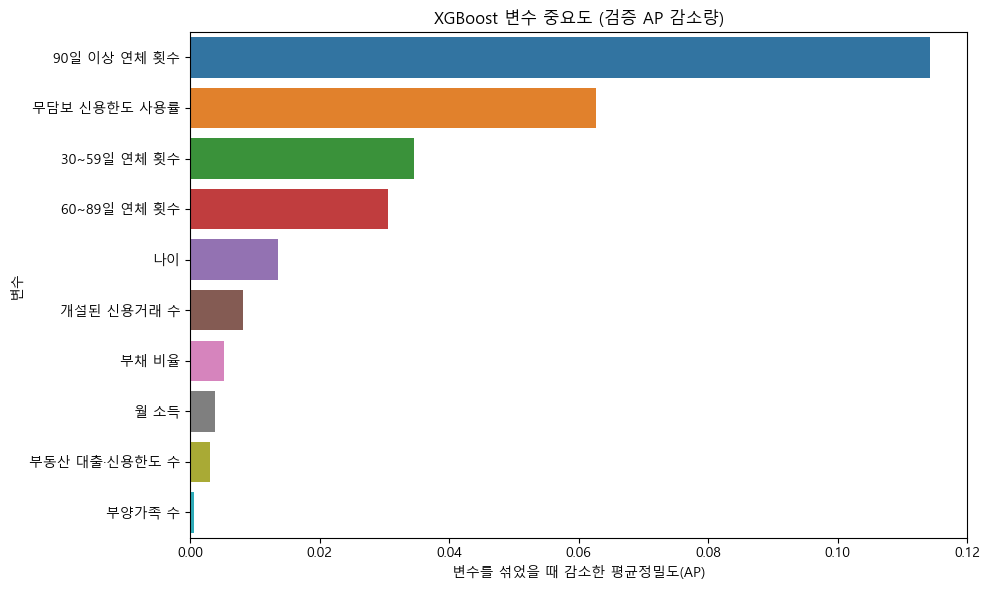

In [ ]:
from sklearn.inspection import permutation_importance

# 검증 데이터에서 각 입력 변수를 섞었을 때 AP가 얼마나 낮아지는지 계산합니다.
importance_result = permutation_importance(
    fitted_models[best_validation_name],
    X_valid,
    y_valid,
    scoring=average_precision_scorer,
    n_repeats=3,
    random_state=42,
    n_jobs=1,
)

# 변수별 평균 AP 감소량과 반복 간 변동을 표로 정리합니다.
permutation_importance_df = pd.DataFrame({
    "변수": X_valid.columns,
    "평균정밀도 감소 평균": importance_result.importances_mean,
    "평균정밀도 감소 표준편차": importance_result.importances_std,
}).sort_values("평균정밀도 감소 평균", ascending=False)

# AP를 가장 많이 낮춘 상위 10개 변수를 표시합니다.
display(permutation_importance_df.head(10).style.format({
    "평균정밀도 감소 평균": "{:.4f}",
    "평균정밀도 감소 표준편차": "{:.4f}",
}))

# 상위 변수의 중요도를 막대그래프로 그립니다.
plt.figure(figsize=(10, 6))
sns.barplot(
    data=permutation_importance_df.head(10),
    x="평균정밀도 감소 평균",
    y="변수",
)
plt.title("XGBoost 변수 중요도 (검증 AP 감소량)")
plt.xlabel("변수를 섞었을 때 감소한 평균정밀도(AP)")
plt.ylabel("변수")
plt.tight_layout()
plt.show()